In [1]:
import sys

print(sys.version)
print(sys.executable)

3.11.16 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:36:16) [MSC v.1942 64 bit (AMD64)]
C:\Users\seanf\anaconda3\envs\elisa\python.exe


In [2]:
import elisa

print(elisa.__version__)

C:\Users\seanf\anaconda3\envs\elisa\Lib\site-packages\elisa\conf\settings.py:408: DeprecationWarning: Variable `atlas` in configuration section `support` is not longer supported and will be removed in future version.
Use atmosphere definition as initial parameter for given celestial object
  warnings.warn("Variable `atlas` in configuration section `support` is not "


2026-08-31 14:16:42,935 - 17968 - matplotlib.font_manager - INFO: generated new fontManager
0.6.2


In [1]:
from elisa import BinarySystem
from elisa import Star
from astropy import units as u

C:\Users\seanf\anaconda3\envs\elisa\Lib\site-packages\elisa\conf\settings.py:408: DeprecationWarning: Variable `atlas` in configuration section `support` is not longer supported and will be removed in future version.
Use atmosphere definition as initial parameter for given celestial object
  warnings.warn("Variable `atlas` in configuration section `support` is not "


In [324]:
primary = Star(
    mass = 2.3 * u.solMass, # mass in solar masses
    surface_potential = 3.3, # tl:dr, size/shape of star, the Roche lobe
    # a dimensionless Roche potential, the effective potential of a star in a binary system, accounting for the gravitational potential  
    # of both stars and the centrifugal potential of the orbiting bodies.
    # the contour line at which the potential is equal to this value is the Roche Lobe.
    
    synchronicity = 1, # ratio between star's rotational period and orbital period
    t_eff = 8000 * u.K, # effective temperature
    # optionals such as albedo, metallicity, gravity darkening (stars being brighter at the poles due to rotation expanding the star at equator)    
)

secondary = Star(
    mass = 0.6 * u.solMass,
    surface_potential = 4.7,
    synchronicity = 1,
    t_eff = 4500 * u.K
)

In [325]:
bs = BinarySystem(
    primary=primary,
    secondary=secondary,
    argument_of_periastron = 46 * u.deg, # the argument of periapsis, but specifically for when the body is a star
    gamma = 29 * u.km / u.s, # the speed at which the entire system is moving through the galaxy, in km/s
    period = 2.6 * u.d, # the orbital period, in days
    eccentricity = 0.0,
    inclination = 73 * u.deg,
    primary_minimum_time = 2440000.0000 * u.d, # the time (in days) at which the light curve is minimum
    phase_shift = 0,
    distance = 178 * u.pc
)

2026-09-09 13:26:07,507 - 43812 - binary_system.system - INFO: initialising object BinarySystem
2026-09-09 13:26:07,662 - 43812 - binary_system.system - INFO: setting discretization factor of secondary component to 8.00 according to discretization factor of the companion.


In [326]:
from elisa import Observer
from elisa import settings

o = Observer(passband=[  # defining passbands at which calculate a light curve
#     'Generic.Bessell.U',
    'Generic.Bessell.B',
    'Generic.Bessell.V',
    'Generic.Bessell.R',
    'Generic.Bessell.I',
                      ],
             system=bs)  # specifying the binary system to use in light curve synthesis



2026-09-09 13:26:08,335 - 43812 - observer.observer - INFO: initialising Observer instance


In [327]:
#settings.PASSBANDS

In [328]:
phases, fluxes = o.observe.lc( # fluxes contains synthetic light curve data for each passband specified in Observer
    from_phase=-0.6,
    to_phase=0.6,
    phase_step=0.01,
    # normalize=True
)

2026-09-09 13:26:11,038 - 43812 - observer.observer - INFO: observation is running
2026-09-09 13:26:12,106 - 43812 - elisa.atm - INFO: time 0.01475667953491211
2026-09-09 13:26:12,112 - 43812 - elisa.atm - INFO: time 0.0008821487426757812
2026-09-09 13:26:12,120 - 43812 - elisa.atm - INFO: time 0.004614591598510742
2026-09-09 13:26:12,126 - 43812 - elisa.atm - INFO: time 0.0011487007141113281
2026-09-09 13:26:12,240 - 43812 - elisa.atm - INFO: time 0.0
2026-09-09 13:26:12,243 - 43812 - elisa.atm - INFO: time 0.0
2026-09-09 13:26:12,248 - 43812 - elisa.atm - INFO: time 0.0
2026-09-09 13:26:12,251 - 43812 - elisa.atm - INFO: time 0.001020193099975586
2026-09-09 13:26:13,844 - 43812 - observer.observer - INFO: observation finished


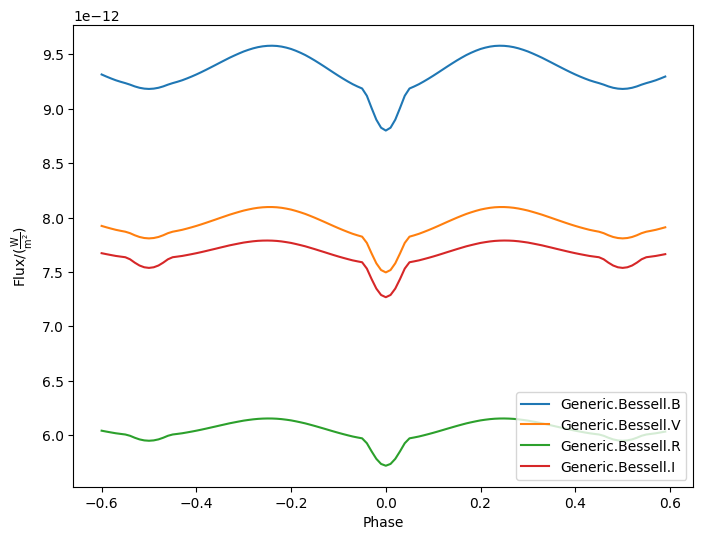

In [329]:
o.plot.phase_curve(phases=phases, fluxes=fluxes)

In [323]:
# creating ranges of possible parameter values
import numpy as np
import random
from scipy import constants
from scipy.optimize import root_scalar

solM = 2*10**30 
solR = 6.96*10**8

# stellar parameters
m1_range=[]
m2_range=[]

F1_range=[]
F2_range=[]

t1_range=[]
t2_range=[]

Omega1_range = []
Omega2_range = []

# orbital parameters

e_range=[]
arg_peri_range=[] #argument of periastron. angle of ascending node to periastron (the closest point to centre).
                  #asc. node is when the orbit body crosses the reference plane heading north
gamma_range=[]
period_range=[]
inc_range=[]
dist_range=[]

for i in range(500):
    m1_kg = random.uniform(0.2*solM,5*solM)
    q = random.uniform(0.1,1) # mass ratio m2/m1
    m2_kg = q * m1_kg
    m1 = m1_kg/(solM) # in solar masses
    m2 = m2_kg/(solM)
    m1_range.append(m1)
    m2_range.append(m2)
    
    gamma=np.random.uniform(15,75) * u.km / u.s
    gamma_range.append(gamma)

    inc=np.random.uniform(50,90) * u.deg # range of i=50 to i=90 degrees, as given in section 7.2.4 in handbook
    inc_range.append(inc)

    dist=np.random.uniform(50,200) * u.pc 
    dist_range.append(dist)
    
    r1 = m1**0.8 if m1 < 1 else m1**0.57  # in solar radii
    r2 = m2**0.8 if m2 < 1 else m2**0.57  # using stellar mass to radius relation

    t1 = (m1_kg)**0.5 
    t2 = (m2_kg)**0.5 # from mass-luminosity relation, into stefan-boltzmann
    t1_range.append(t1)
    t2_range.append(t2)

    arg_peri = np.random.uniform(0,360) # can be anything from 0 to 360 deg, as given by the handbook when testing in sec 7.2.4.
    arg_peri_range.append(arg_peri)

    q_inv = 1/q # Eggleton uses q = m1/m2, we use q = m2/m1
    # approximating Roche Lobe Radius as a sphere, using Eggleton 1983:
    r_L1 = (0.49*q_inv**(2/3))/(0.6*q_inv**(2/3) + np.log(1+q_inv**(1/3))) # normalised by semi-major axis, i think
    # r_L1. If r_1 < r_L1, then it is detached
    # if r_1 = r_L1, it is semidetached
    # if r_1 > r_L1, it is overcontact (i.e. the star has exceeded its Roche lobe)
    

    type = np.random.randint(1,4) # determines if system is detached, semi-detached or contact

    if type == 1: # detached
        a_max = (r1 * solR) / (0.1*r_L1) # prevents the a-normalised radius from being too tiny
        # star's normalised radius must fit at least 10% of the Roche lobe
    
        a_min = (r1*solR+r2*solR)/(0.95*(1-e)) # prevents stars from physically colliding at periastron
        # both stars' combined radius cannot be greater than 95% of the distance between star centres at periastron
    
        if a_min > a_max:
            continue
        
        a = np.random.uniform(a_min,a_max) # randomly sample semi-major axis within boundaries
        period = ((4*np.pi**2)/constants.G * (m1+m2) * a**3)**(0.5)
        period_range.append(period)
        
        e = random.uniform(0.0,0.5) # eccentricity
        e_range.append(e)
    
        F_theory = (1 + e)**2 / (1 - e**2)**(3/2) # theoretically, F_1 and F_2 are the same
    
        # sampling synchronicity with small scatter
        F_1 = np.random.normal(F_theory,0.05)
        F_2 = np.random.normal(F_theory,0.05)
        F1_range.append(F_1)
        F2_range.append(F_2)
        
        #d_min = 1 - e # periastron distance (closest point in orbit to centre of mass), in unitless distance normalised to semi-major axis
        #d_max = 1 + e # apastron distance (furthest point from centre of mass)
    
        d = 1 # calculating surface potential at normalised distance = 1
    
        rho_1 = r1*solR / a
        rho_2 = r2*solR / a # radii normalised by semi-major axis
    
        Omega1 = 1/rho_1 + q*(1/(d - rho_1) - rho_1/(d)**2) + 1/2 * F_1**2 *(1+q)*rho_1**2
        # under same conditions as omega1; d=1, lambda=1, theta=0. Using rho_2 instead of rho_1 Following equation (8) in elisa handbook:
        Omega2 = q/rho_2 + 1/(d**2 - 2*d*rho_2 + rho_2**2)**(0.5) - rho_2/d**2 + 0.5*F_2**2 * (q+1)*rho_2**2 + 0.5*(1-q)
        Omega1_range.append(Omega1)
        Omega2_range.append(Omega2)

    elif type==2: # semi-detached
        
        e = np.random.uniform(0,0.1) # semi-detached systems would have low eccentricities
        e_range.append(e)

        F_theory = (1 + e)**2 / (1 - e**2)**(3/2) 
        F_1 = np.random.normal(F_theory,0.05)
        F_2 = np.random.normal(F_theory,0.05)
        F1_range.append(F_1)
        F2_range.append(F_2)
        
        rho_1 = r_L1 # primary radius fits exactly within Roche lobe

        d=1
        Omega1 = 1/rho_1 + q*(1/(d - rho_1) - rho_1/(d)**2) + 1/2 * F_1**2 *(1+q)*rho_1**2
        Omega2 = q/rho_2 + 1/(d**2 - 2*d*rho_2 + rho_2**2)**(0.5) - rho_2/d**2 + 0.5*F_2**2 * (q+1)*rho_2**2 + 0.5*(1-q)
        Omega1_range.append(Omega1)
        Omega2_range.append(Omega2)
        
        # a = ??
        period = ((4*np.pi**2)/constants.G * (m1+m2) * a**3)**(0.5)
        period_range.append(period)
    else: # overcontact

        e=0 # close binary orbits tend to circular orbits (Zahn 1975)
        e_range.append(e)
        F_1 = F_2 = 1 # close binary stars synchronise fast; on a scale much shorter than nuclear (Zahn 1977)
        F1_range.append(F_1)
        F2_range.append(F_2)
        # here Omega_1 lies between Omega_L1 and Omega_L2
        #Omega_L1 = 1/r_L1 + q*(1/(d - r_L1) - r_L1/(d)**2) + 1/2 * F_1**2 *(1+q)*r_L1**2
        
        # using scipy root finding method to calculate Omega_L2:
        #Omega_L2_1st_deriv = lambda r: -1/r**2 - q/(r-1)**2 - q + (1+q)*r # the first derivative of Omega_L2, with respect to r
        #r_L2 = root_scalar(Omega_L2_1st_deriv, bracket=[1.00001,3.0]).root # search for root. lower bound of 1 orbital separation, upper of 3 orbital separations.
        #Omega_L2 = 1/r_L2 + q*(1/(d - r_L2) - r_L2/(d)**2) + 1/2 * F_1**2 *(1+q)*r_L2**2 # plugs the root back into the equation for Omega, with e=0 and F=1

        #Omega_1 = np.random.uniform(Omega_L1,Omega_L2)

        #a = ??
        period = ((4*np.pi**2)/constants.G * (m1+m2) * a**3)**(0.5)
        period_range.append(period)
        
        Omega1 = 1/rho_1 + q*(1/(d - rho_1) - rho_1/(d)**2) + 1/2 * F_1**2 *(1+q)*rho_1**2
        Omega2 = q/rho_2 + 1/(d**2 - 2*d*rho_2 + rho_2**2)**(0.5) - rho_2/d**2 + 0.5*F_2**2 * (q+1)*rho_2**2 + 0.5*(1-q)
        Omega1_range.append(Omega1)
        Omega2_range.append(Omega2)

In [322]:
for i in range(len(period)):
    primary = Star(
        mass = m1_range[i],
        surface_potential = Omega1_range[i], 
        synchronicity = F1_range[i], 
        t_eff = t1_range[i]
    )

    secondary = Star(
        mass = m2_range[i],
        surface_potential = Omega2_range[i],
        synchronicity = F2_range[i],
        t_eff = t2_range[i]
    )

    bs = BinarySystem(
        primary=primary,
        secondary=secondary,
        argument_of_periastron = arg_peri_range[i],
        gamma = gamma_range[i],
        period = period_range[i],
        eccentricity = e_range[i],
        inclination = inc_range[i],
        primary_minimum_time = 2440000.0000 * u.d, 
        phase_shift = 0,
        distance = dist_range[i]
    )
        

IndexError: list index out of range